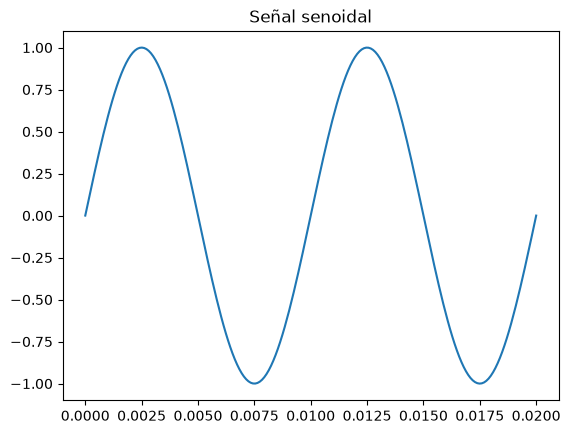

In [2]:
import numpy as np
import matplotlib.pyplot as plt

Fs = 10000
N = 200
t = np.linspace(0, N / Fs, num = N)

f = 100
A = 1

signal = A * np.sin(2 * np.pi * f * t)

plt.title("Señal senoidal")
plt.plot(t, signal)
plt.show()

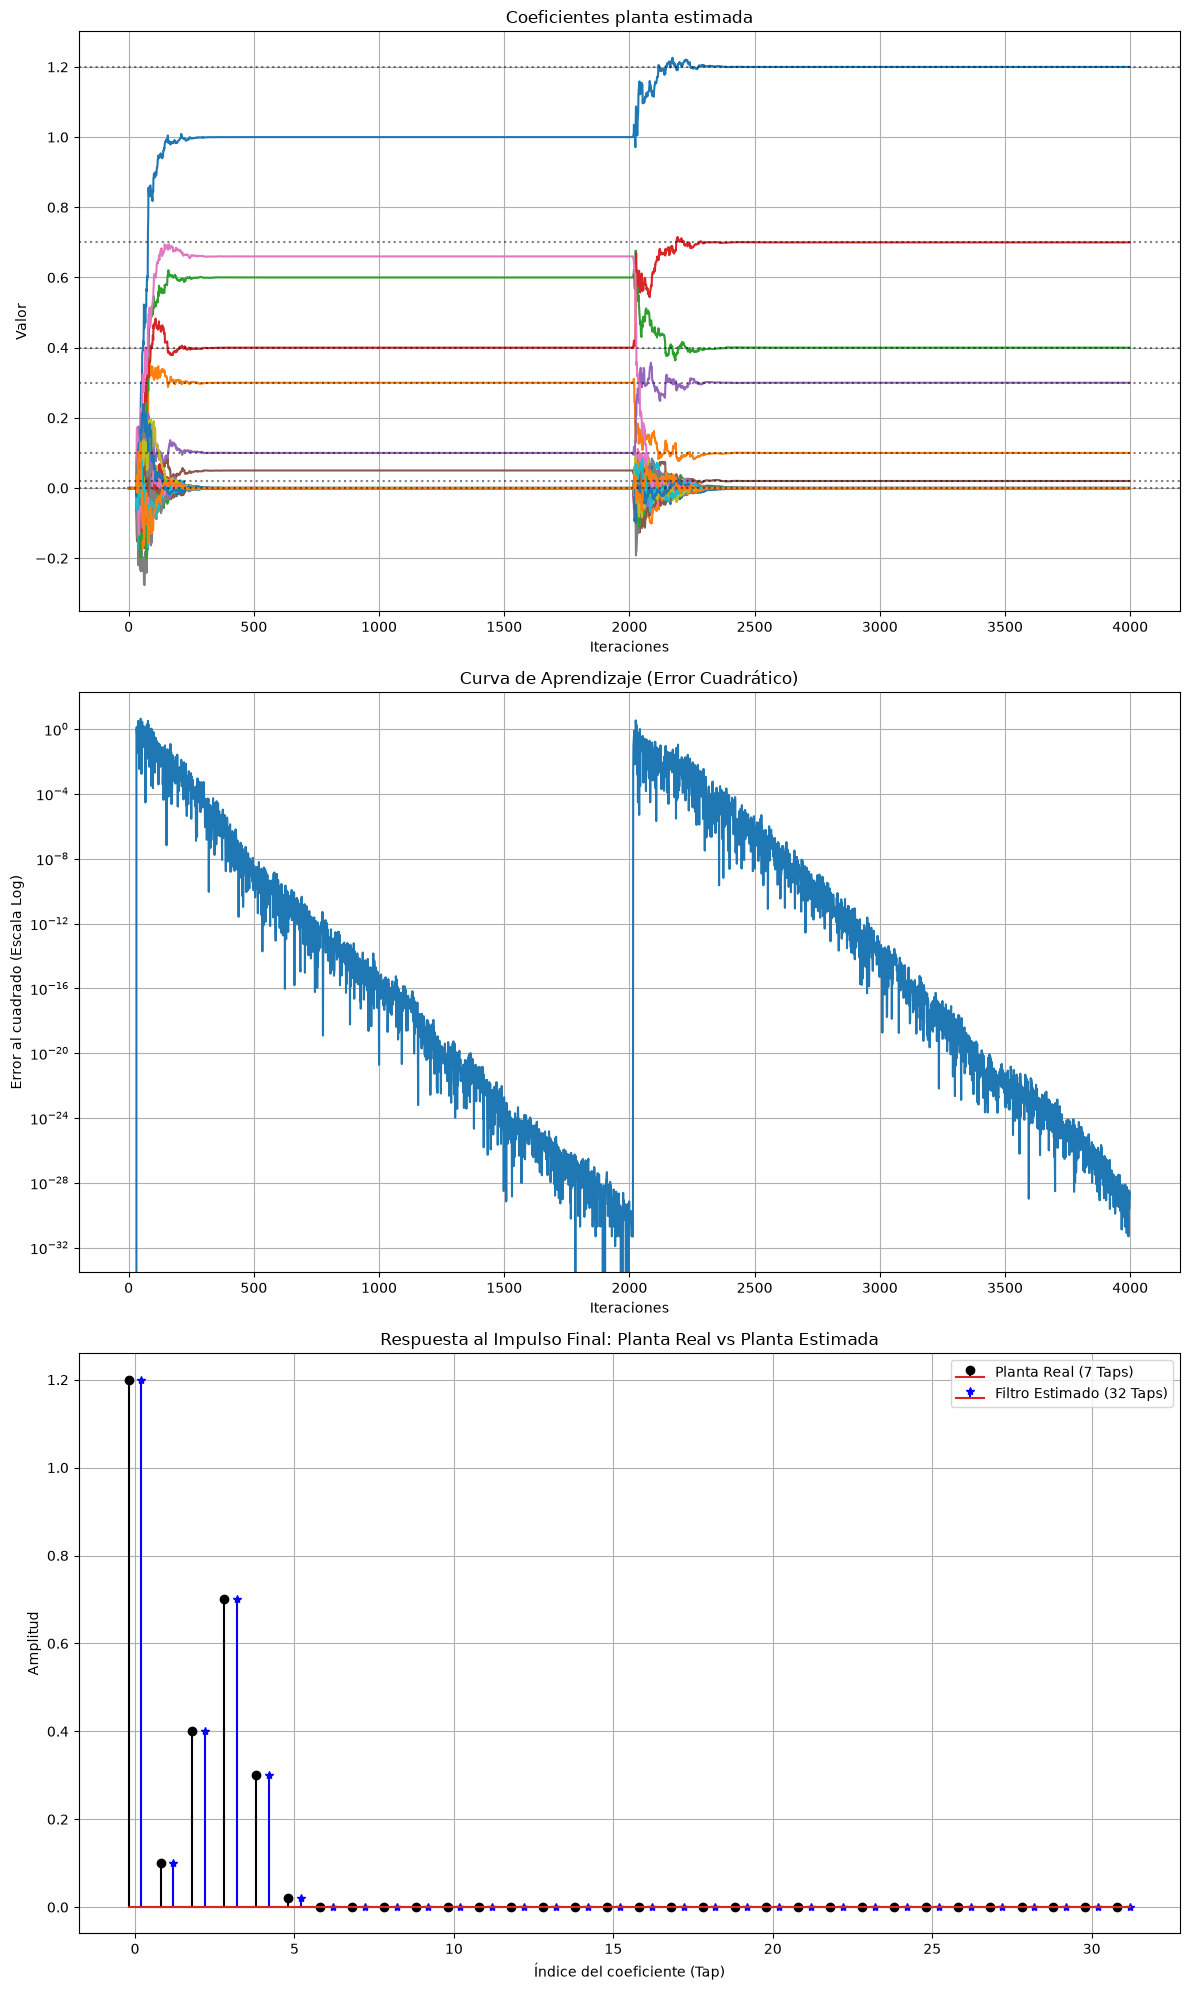

In [6]:
import numpy as np
import matplotlib.pyplot as plt

N_muestras = 4000   # Iteraciones
mu = 0.018           # Velocidad de aprendizaje

planta_real = np.array([1, 0.3, 0.6, 0.4, 0.1, 0.05, 0.66])   # Planta a estimar
orden_planta = len(planta_real) # Orden de la planta real
orden_filtro = 32   # Orden del filtro que va a estimar a la planta

np.random.seed(34)
x = np.random.normal(0, 1, N_muestras)

# Generamos la salida de la planta real que se va a medir con el ADC
d = np.zeros(N_muestras)
for i in range(orden_planta - 1, N_muestras):
    if i == (orden_filtro + N_muestras - 2) // 2:
        planta_real = np.array([1.2, 0.1, 0.4, 0.7, 0.3, 0.02, 0])
    x_input = x[i - orden_planta + 1 : i + 1][::-1]
    d[i] = np.dot(planta_real, x_input)

w = np.zeros(orden_filtro)  # Coeficientes del filtro
historial_w = np.zeros((N_muestras, orden_filtro))
y = np.zeros(N_muestras)    # Salida del filtro
e = np.zeros(N_muestras)    # Error del filtro

planta_real = np.array([1, 0.3, 0.6, 0.4, 0.1, 0.05, 0.66])
# Ciclo LMS
for i in range(orden_filtro - 1, N_muestras):
    if i == (orden_filtro + N_muestras - 2) // 2:
        planta_real = np.array([1.2, 0.1, 0.4, 0.7, 0.3, 0.02, 0])
    x_input = x[i - orden_filtro + 1 : i + 1][::-1]
    y[i] = np.dot(w, x_input)
    e[i] = d[i] - y[i]
    w = w + 2 * mu * e[i] * x_input
    historial_w[i, :] = w

plt.figure(figsize=(12,20))

plt.subplot(3, 1, 1)
plt.title("Coeficientes planta estimada")
plt.xlabel("Iteraciones")
plt.ylabel("Valor")
for k in range(orden_filtro):
    plt.plot(historial_w[:, k])
    # Línea punteada que muestra el valor real al que debe llegar
for k in range(orden_planta):
    plt.axhline(y=planta_real[k], color='black', linestyle=':', alpha=0.5)
plt.grid()

plt.subplot(3, 1, 2)
plt.title("Curva de Aprendizaje (Error Cuadrático)")
plt.yscale('log') 
plt.xlabel("Iteraciones")
plt.ylabel("Error al cuadrado (Escala Log)")
plt.plot(e**2)
plt.grid()

plt.subplot(3, 1, 3)
plt.title("Respuesta al Impulso Final: Planta Real vs Planta Estimada")
planta_real_padded = np.zeros(orden_filtro) # Se llenan las 64 muestras de la planta con ceros
planta_real_padded[:orden_planta] = planta_real
indices = np.arange(orden_filtro)
plt.stem(indices - 0.2, planta_real_padded, linefmt='k-', markerfmt='ko', label=f'Planta Real ({orden_planta} Taps)')
plt.stem(indices + 0.2, w, linefmt='b-', markerfmt='b*', label=f'Filtro Estimado ({orden_filtro} Taps)')
plt.xlabel("Índice del coeficiente (Tap)")
plt.ylabel("Amplitud")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


